# Predictive Insight Engine: House Price Estimation

This notebook follows the project brief from concept to model comparison. The aim is to estimate `house_price_inr` and understand which model is useful without hiding the checks behind a single accuracy number.

**Questions this notebook answers**

- How do the main property variables relate to price?
- What changes when one feature is replaced by several features?
- Does a polynomial model improve the fit or start to overfit?
- Do batch, stochastic and mini-batch gradient descent reach similar solutions?

## Part A - Short theory notes

**Supervised learning** learns a relationship from examples where both the inputs and the correct output are known. In this project the inputs are property features and the known output is the recorded house price.

**Regression vs classification:** regression predicts a numeric quantity such as price, while classification predicts a category such as low, medium or high. House price is therefore a regression problem.

**Simple linear regression** models one input with a line, `y_hat = b0 + b1*x`. The intercept is the predicted value when the feature is zero, and the slope is the expected change in price for a one-unit increase in that feature.

**Main assumptions:** a roughly linear relationship, independent observations, constant error variance, limited influence from extreme outliers, and residuals that are approximately normal when inference is required. Predictors should also not be strongly redundant in a multiple model.

**Bias and variance:** a high-bias model is too simple and misses the pattern; a high-variance model follows the training sample too closely. The useful model is usually a compromise that performs well on unseen data.

**Overfitting and underfitting:** a very flexible model can have excellent training results but poor test results, which is overfitting. A model that performs poorly on both is underfitting.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
DATA_PATH = Path("RealEstate_HousePrice_Dataset_4200 - RealEstate_HousePrice_Dataset_4200.csv.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Could not find {DATA_PATH.resolve()}")

df = pd.read_csv(DATA_PATH)
df.head()

,house_id,area_sqft,bedrooms,bathrooms,location_score,age_years,distance_city_km,lot_size_sqft,has_garage,has_pool,renovation_years_ago,house_price_inr
0,100001,1973,5,4,7.6,23,11.9,5220,1,0,0,40275084
1,100002,1560,3,3,6.3,13,15.8,3882,1,0,13,26812029
2,100003,2071,4,3,5.8,9,21.1,4488,0,0,9,29315677
3,100004,2640,5,3,7.7,12,7.9,3614,1,1,4,47712959
4,100005,1498,3,3,3.8,15,24.0,2663,0,0,15,17724566


In [2]:
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
display(df.dtypes.to_frame("dtype"))
display(df.describe().T.round(2))
print("Missing values by column:")
display(df.isna().sum().to_frame("missing"))

Rows: 4,200 | Columns: 12


,dtype
house_id,int64
area_sqft,int64
bedrooms,int64
bathrooms,int64
location_score,float64
age_years,int64
distance_city_km,float64
lot_size_sqft,int64
has_garage,int64
has_pool,int64


,count,mean,std,min,25%,50%,75%,max
house_id,4200.0,102100.50,1212.58,100001.0,101050.75,102100.5,103150.25,104200.0
area_sqft,4200.0,1667.36,630.34,450.0,1226.75,1660.0,2084.25,4202.0
bedrooms,4200.0,3.70,1.57,1.0,3.00,4.0,5.00,7.0
bathrooms,4200.0,2.83,1.15,1.0,2.00,3.0,4.00,6.0
location_score,4200.0,5.61,2.14,1.0,4.00,5.7,7.30,10.0
age_years,4200.0,23.83,13.95,1.0,13.00,21.0,32.00,80.0
distance_city_km,4200.0,18.19,8.67,1.0,11.80,17.8,24.20,47.6
lot_size_sqft,4200.0,3366.33,1658.23,800.0,2122.50,3188.0,4364.25,12938.0
has_garage,4200.0,0.64,0.48,0.0,0.00,1.0,1.00,1.0
has_pool,4200.0,0.10,0.29,0.0,0.00,0.0,0.00,1.0


Missing values by column:


,missing
house_id,0
area_sqft,0
bedrooms,0
bathrooms,0
location_score,0
age_years,0
distance_city_km,0
lot_size_sqft,0
has_garage,0
has_pool,0


## Part B - Dataset understanding

The dependent variable is `house_price_inr`. The independent variables are the property measurements and amenity flags. `house_id` is deliberately excluded because its number does not describe the house.

Features used: ['area_sqft', 'bedrooms', 'bathrooms', 'location_score', 'age_years', 'distance_city_km', 'lot_size_sqft', 'has_garage', 'has_pool', 'renovation_years_ago']


c:\Users\mitan\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


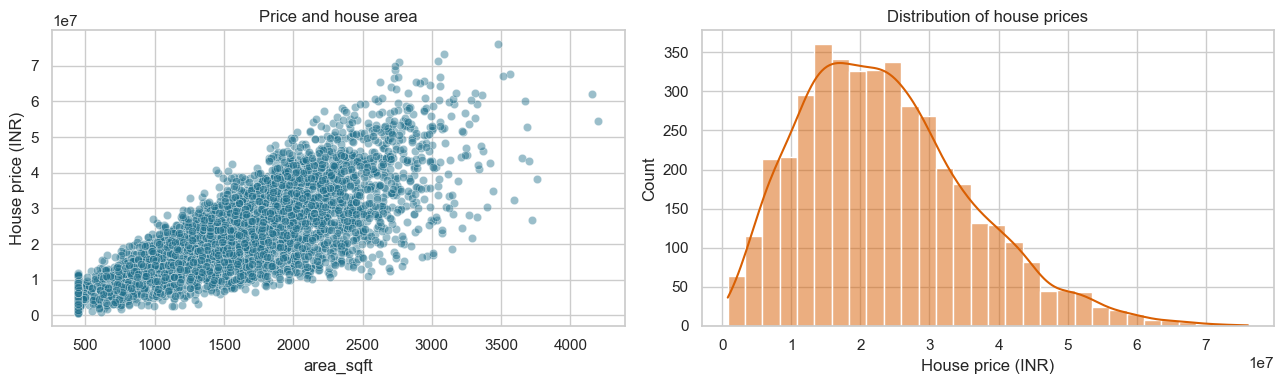

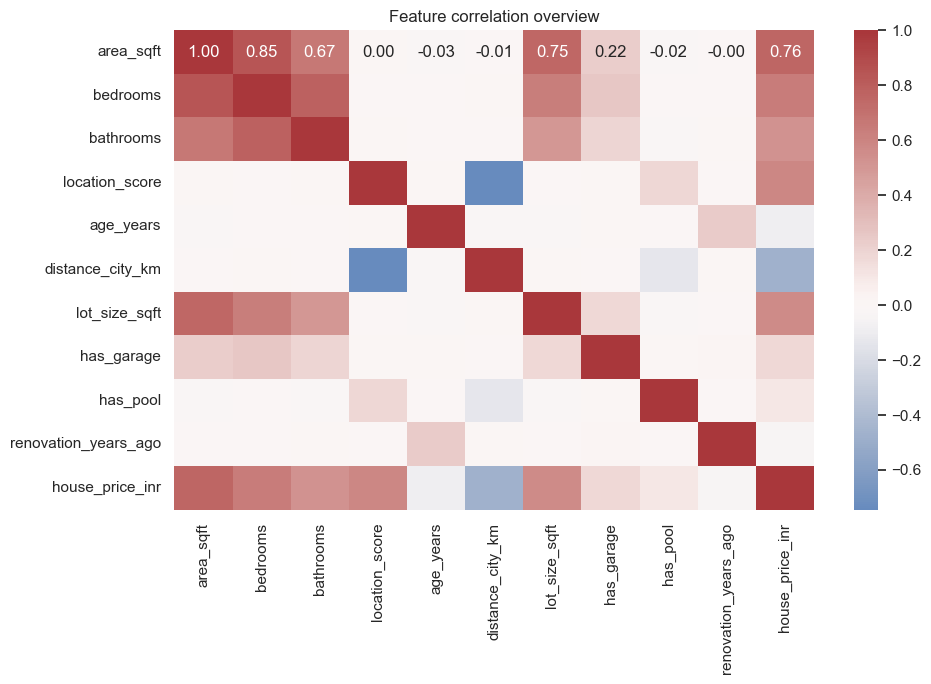

In [3]:
target = "house_price_inr"
id_column = "house_id"
feature_columns = [column for column in df.columns if column not in [target, id_column]]
X = df[feature_columns].copy()
y = df[target].copy()
print("Features used:", feature_columns)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.scatterplot(data=df, x="area_sqft", y=target, alpha=0.45, ax=axes[0], color="#1f6f8b")
axes[0].set_title("Price and house area")
axes[0].set_ylabel("House price (INR)")
sns.histplot(y, bins=30, kde=True, ax=axes[1], color="#d95f02")
axes[1].set_title("Distribution of house prices")
axes[1].set_xlabel("House price (INR)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 7))
correlations = df[feature_columns + [target]].corr(numeric_only=True)
sns.heatmap(correlations, cmap="vlag", center=0, annot=True, fmt=".2f")
plt.title("Feature correlation overview")
plt.tight_layout()
plt.show()

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print(f"Training rows: {len(X_train):,}")
print(f"Testing rows: {len(X_test):,}")

Training rows: 3,360
Testing rows: 840


## Parts C and D - Simple linear regression and metrics

This first model uses only house area. Its slope is useful to discuss, but it should not be interpreted as a causal price increase because other property differences are still mixed into the relationship.

Slope: INR 14,788.31 per square foot
Intercept: INR -1,163,519.18


,MSE,MAE,RMSE,R2,Adjusted R2
Simple linear,6.698926e+13,6294593.7,8184696.7,0.56,0.56


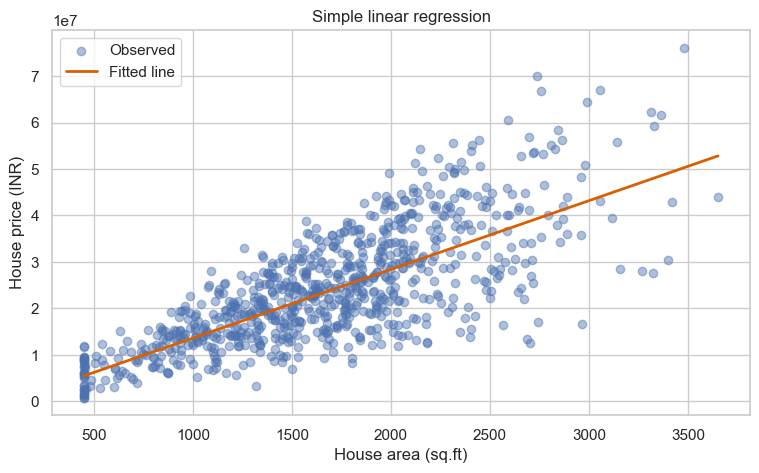

In [5]:
def adjusted_r2(actual, predicted, number_of_features):
    observations = len(actual)
    r2 = r2_score(actual, predicted)
    return 1 - (1 - r2) * (observations - 1) / (observations - number_of_features - 1)

def regression_metrics(actual, predicted, number_of_features):
    return {
        "MSE": mean_squared_error(actual, predicted),
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted),
        "Adjusted R2": adjusted_r2(actual, predicted, number_of_features),
    }

simple_model = LinearRegression()
simple_model.fit(X_train[["area_sqft"]], y_train)
simple_predictions = simple_model.predict(X_test[["area_sqft"]])
simple_scores = regression_metrics(y_test, simple_predictions, 1)
print(f"Slope: INR {simple_model.coef_[0]:,.2f} per square foot")
print(f"Intercept: INR {simple_model.intercept_:,.2f}")
display(pd.DataFrame([simple_scores], index=["Simple linear"]).round(2))

plot_order = np.argsort(X_test["area_sqft"].values)
plt.figure(figsize=(9, 5))
plt.scatter(X_test["area_sqft"], y_test, alpha=0.45, label="Observed")
plt.plot(X_test["area_sqft"].values[plot_order], simple_predictions[plot_order], color="#d95f02", linewidth=2, label="Fitted line")
plt.xlabel("House area (sq.ft)")
plt.ylabel("House price (INR)")
plt.title("Simple linear regression")
plt.legend()
plt.show()

### How to read the metrics

MSE squares errors and therefore emphasizes large misses. MAE is the average absolute price error and is easier to explain in business terms. RMSE is in INR and penalizes large errors more than MAE. R-squared is the fraction of target variation explained by the model, while adjusted R-squared also accounts for how many predictors were added.

## Part E - Multiple linear regression

The multiple model uses the measured property features together. Comparing its test metrics with the simple model shows whether the additional information is useful out of sample.

,MSE,MAE,RMSE,R2,Adjusted R2
Multiple linear,1.259292e+13,2604991.41,3548650.29,0.92,0.92


,coefficient
distance_city_km,-98965.16
age_years,-65609.24
renovation_years_ago,-21435.91
lot_size_sqft,103.51
area_sqft,13795.94
has_garage,93924.36
bathrooms,185944.54
bedrooms,197643.11
has_pool,455290.23
location_score,3073173.50


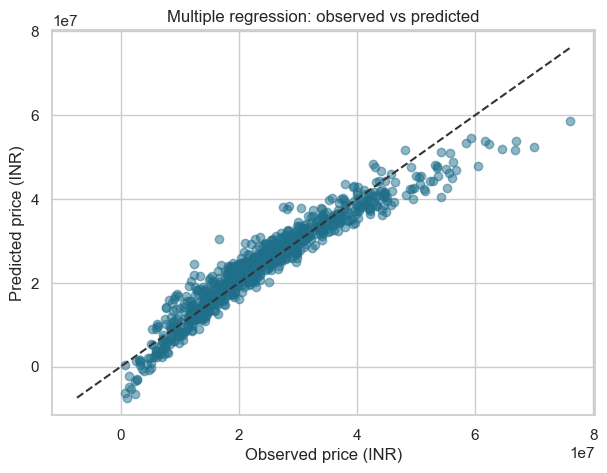

In [6]:
multiple_model = LinearRegression()
multiple_model.fit(X_train, y_train)
multiple_predictions = multiple_model.predict(X_test)
multiple_scores = regression_metrics(y_test, multiple_predictions, X_test.shape[1])

multiple_coefficients = pd.Series(multiple_model.coef_, index=feature_columns).sort_values()
display(pd.DataFrame([multiple_scores], index=["Multiple linear"]).round(2))
display(multiple_coefficients.to_frame("coefficient").round(2))

plt.figure(figsize=(7, 5))
plt.scatter(y_test, multiple_predictions, alpha=0.5, color="#1f6f8b")
limits = [min(y_test.min(), multiple_predictions.min()), max(y_test.max(), multiple_predictions.max())]
plt.plot(limits, limits, linestyle="--", color="#333333")
plt.xlabel("Observed price (INR)")
plt.ylabel("Predicted price (INR)")
plt.title("Multiple regression: observed vs predicted")
plt.show()

## Part F - Polynomial regression

Polynomial features allow curved relationships, but they also increase flexibility. Standardization is included in the pipeline so the expanded features are on a reasonable numerical scale.

In [7]:
polynomial_results = []
polynomial_models = {}
for degree in [2, 3]:
    model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        StandardScaler(),
        LinearRegression(),
    )
    model.fit(X_train, y_train)
    train_predictions = model.predict(X_train)
    test_predictions = model.predict(X_test)
    polynomial_models[degree] = model
    polynomial_results.append({
        "Model": f"Polynomial degree {degree}",
        "Train R2": r2_score(y_train, train_predictions),
        "Test R2": r2_score(y_test, test_predictions),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, test_predictions)),
        "Test MAE": mean_absolute_error(y_test, test_predictions),
    })

polynomial_table = pd.DataFrame(polynomial_results).set_index("Model")
display(polynomial_table.round(2))
print("A large train/test R2 gap is a warning sign for overfitting.")

,Train R2,Test R2,Test RMSE,Test MAE
Model,,,,
Polynomial degree 2,0.97,0.97,2297552.47,1685541.05
Polynomial degree 3,0.97,0.96,2329180.88,1710571.29


A large train/test R2 gap is a warning sign for overfitting.


## Part G - Gradient descent from scratch

For optimization, the predictors are standardized and a column of ones is added for the intercept. The code below uses mean squared error as the loss. Batch gradient descent sees the complete training set on each update, SGD sees one randomly selected observation, and mini-batch uses a small random group.

,MSE,MAE,RMSE,R2,Adjusted R2
Method,,,,,
batch,1.260736e+13,2606311.46,3550684.34,0.92,0.92
sgd,5.595987e+14,22182504.80,23655839.13,-2.65,-2.70
mini-batch,1.288302e+13,2618058.27,3589292.29,0.92,0.91


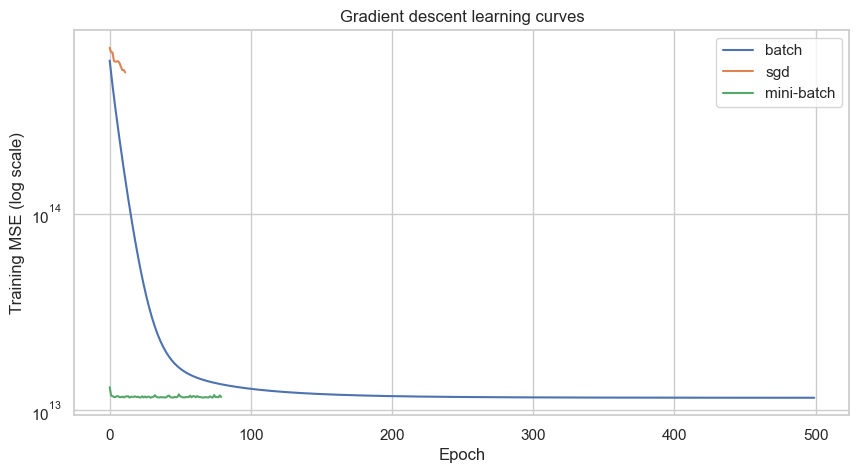

In [8]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
X_train_gd = np.c_[np.ones(len(X_train_scaled)), X_train_scaled]
X_test_gd = np.c_[np.ones(len(X_test_scaled)), X_test_scaled]

def gradient_descent(X_values, y_values, learning_rate=0.03, epochs=500, method="batch", batch_size=32, seed=42):
    rng = np.random.default_rng(seed)
    coefficients = np.zeros(X_values.shape[1])
    history = []
    for _ in range(epochs):
        if method == "batch":
            batches = [np.arange(len(X_values))]
        elif method == "sgd":
            batches = [rng.integers(0, len(X_values), size=1)]
        else:
            shuffled = rng.permutation(len(X_values))
            batches = [shuffled[start:start + batch_size] for start in range(0, len(X_values), batch_size)]
        for batch_indices in batches:
            batch_X = X_values[batch_indices]
            batch_y = y_values.iloc[batch_indices].to_numpy()
            errors = batch_X @ coefficients - batch_y
            gradient = (2 / len(batch_indices)) * batch_X.T @ errors
            coefficients -= learning_rate * gradient
        full_errors = X_values @ coefficients - y_values.to_numpy()
        history.append(np.mean(full_errors ** 2))
    return coefficients, history

def gd_predict(X_values, coefficients):
    return X_values @ coefficients

gd_results = []
gd_models = {}
for method, learning_rate, epochs in [("batch", 0.03, 500), ("sgd", 0.003, 12), ("mini-batch", 0.03, 80)]:
    coefficients, history = gradient_descent(
        X_train_gd, y_train, learning_rate=learning_rate, epochs=epochs,
        method=method, batch_size=32, seed=RANDOM_STATE
    )
    predictions = gd_predict(X_test_gd, coefficients)
    scores = regression_metrics(y_test, predictions, X_test.shape[1])
    gd_models[method] = (coefficients, history)
    gd_results.append({"Method": method, **scores})

gd_table = pd.DataFrame(gd_results).set_index("Method")
display(gd_table.round(2))

plt.figure(figsize=(10, 5))
for method, (_, history) in gd_models.items():
    plt.plot(history, label=method)
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Training MSE (log scale)")
plt.title("Gradient descent learning curves")
plt.legend()
plt.show()

Batch updates are steady but require a full pass before every step. SGD makes noisy, frequent updates and can be quick on large data, although its path is less smooth. Mini-batch is a practical compromise because it gets some of the speed of SGD while keeping a more stable gradient.

## Part H - Bias-variance and diagnostics

The next table puts the main models on the same scale. The training/test gap is a simple diagnostic: a small gap with poor scores suggests bias, while a large gap suggests variance or overfitting.

,Train R2,Test R2,Test RMSE,Test MAE,R2 gap
Model,,,,,
Polynomial degree 2,0.967,0.966,2297552.465,1685541.048,0.002
Polynomial degree 3,0.971,0.965,2329180.881,1710571.292,0.007
Multiple linear,0.925,0.918,3548650.290,2604991.406,0.007
Simple linear,0.572,0.563,8184696.697,6294593.696,0.010


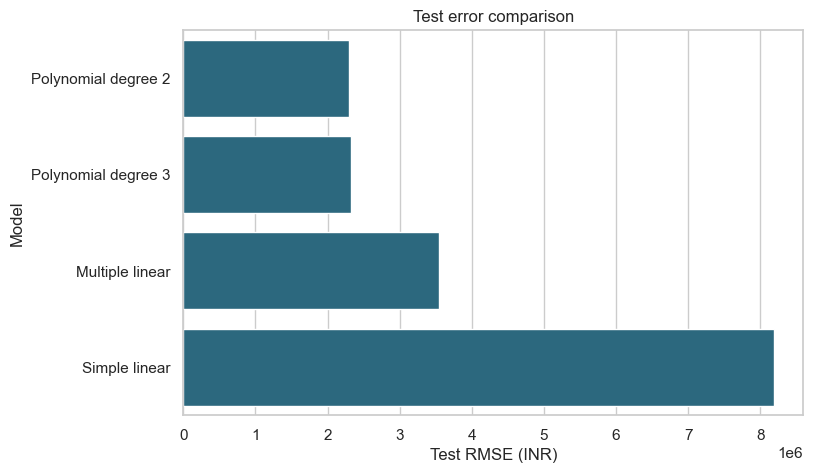

In [9]:
comparison_rows = []
model_predictions = {
    "Simple linear": (simple_model.predict(X_train[["area_sqft"]]), simple_predictions, 1),
    "Multiple linear": (multiple_model.predict(X_train), multiple_predictions, X_train.shape[1]),
}
for degree, model in polynomial_models.items():
    model_predictions[f"Polynomial degree {degree}"] = (
        model.predict(X_train), model.predict(X_test), model.named_steps["polynomialfeatures"].n_output_features_
    )
for model_name, (train_pred, test_pred, feature_count) in model_predictions.items():
    comparison_rows.append({
        "Model": model_name,
        "Train R2": r2_score(y_train, train_pred),
        "Test R2": r2_score(y_test, test_pred),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, test_pred)),
        "Test MAE": mean_absolute_error(y_test, test_pred),
        "R2 gap": r2_score(y_train, train_pred) - r2_score(y_test, test_pred),
    })
comparison = pd.DataFrame(comparison_rows).set_index("Model").sort_values("Test RMSE")
display(comparison.round(3))

plt.figure(figsize=(8, 5))
sns.barplot(data=comparison.reset_index(), x="Test RMSE", y="Model", color="#1f6f8b")
plt.xlabel("Test RMSE (INR)")
plt.title("Test error comparison")
plt.show()

,Degree,Train RMSE,Test RMSE
0,1,3400098.88,3548650.29
1,2,2235162.69,2297552.47
2,3,2103597.53,2329180.88
3,4,1834601.10,3342936.21


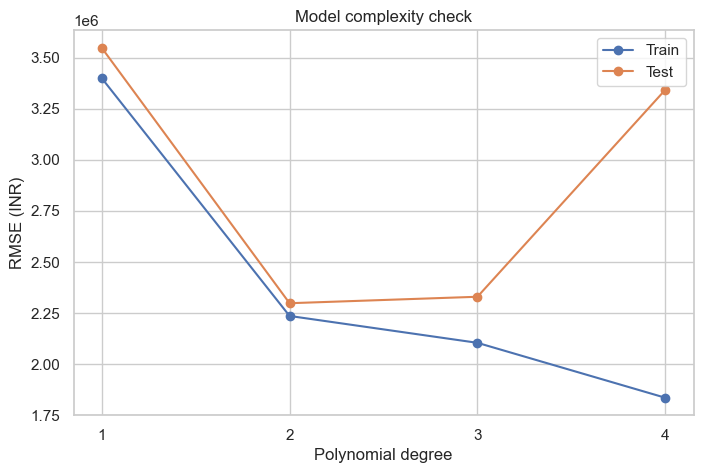

In [10]:
complexity_rows = []
for degree in range(1, 5):
    model = make_pipeline(PolynomialFeatures(degree=degree, include_bias=False), StandardScaler(), LinearRegression())
    model.fit(X_train, y_train)
    complexity_rows.append({
        "Degree": degree,
        "Train RMSE": np.sqrt(mean_squared_error(y_train, model.predict(X_train))),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, model.predict(X_test))),
    })
complexity = pd.DataFrame(complexity_rows)
display(complexity.round(2))
plt.figure(figsize=(8, 5))
plt.plot(complexity["Degree"], complexity["Train RMSE"], marker="o", label="Train")
plt.plot(complexity["Degree"], complexity["Test RMSE"], marker="o", label="Test")
plt.xlabel("Polynomial degree")
plt.ylabel("RMSE (INR)")
plt.title("Model complexity check")
plt.xticks(complexity["Degree"])
plt.legend()
plt.show()